# Bicycle Sales & Shipping Performance Analysis

## Project overview

This portfolio project uses SQL and Python to examine sales revenue, product-category inventory, and shipping timeliness in a bicycle retail dataset.

**Questions:** Which product categories and products contribute most to recorded revenue? How does inventory allocation compare with shipped revenue? What share of shipped orders were shipped after the required date, and how does the rate vary by store and over time?

**Tools:** SQL Server (analysis queries in `../sql/`), Python, pandas, and Matplotlib.

**Data note:** The source database is provided in the DataCamp DataLab environment. The raw database is not redistributed here. The `data/processed/` folder contains aggregate query results used to reproduce the tables and charts in this notebook; it excludes customer-level records.

**Metric definition:** A late shipment is an order with `shipped_date > required_date`. Only orders with a non-null `shipped_date` are included in late-shipment rates. The dataset does not contain an actual customer delivery date, so this analysis does not measure confirmed late delivery.

## 1. Data scope and quality

The data spans order dates from 2016 through 2018. Shipment-date coverage is high in 2016 and 2017 but substantially lower in 2018. This limitation affects interpretation of year-over-year shipping rates.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Supports execution from either the repository root or the notebooks/ directory.
CWD = Path.cwd()
ROOT = CWD if (CWD / "data" / "processed").exists() else CWD.parent
DATA_DIR = ROOT / "data" / "processed"
IMAGE_DIR = ROOT / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

def load_table(filename):
    return pd.read_csv(DATA_DIR / filename)

dataset_overview = load_table("dataset_overview.csv")
order_status_counts = load_table("order_status_counts.csv")
order_status_coverage = load_table("order_status_shipment_coverage.csv")
orders_by_year_status = load_table("orders_by_year_and_status.csv")
sales_by_category = load_table("sales_by_category.csv")
revenue_share = load_table("revenue_share_by_category.csv")
top_products_all = load_table("top_products_all_order_items.csv")
top_products_shipped = load_table("top_products_shipped_orders.csv")
shipped_revenue_by_category = load_table("shipped_revenue_by_category.csv")
inventory_by_category = load_table("inventory_by_category.csv")
inventory_vs_revenue = load_table("inventory_vs_shipped_revenue.csv")
overall_shipping = load_table("overall_shipping_performance.csv")
overall_shipping_split = load_table("overall_shipping_status_split.csv")
shipping_by_store = load_table("shipping_performance_by_store.csv")
annual_shipping = load_table("annual_shipping_performance.csv")
shipping_coverage = load_table("shipping_date_coverage_by_year.csv")
monthly_shipping = load_table("monthly_shipping_performance.csv")

print("Dataset overview")
display(dataset_overview)
print("Order counts by status")
display(order_status_counts)
print("Shipment-date availability by order status")
display(order_status_coverage)

Dataset overview


,total_orders,first_order_date,last_order_date
0,1615,2016-01-01T00:00:00.000,2018-12-28T00:00:00.000


Order counts by status


,order_status,number_of_orders
0,4,1445
1,2,63
2,1,62
3,3,45


Shipment-date availability by order status


,order_status,total_orders,shipped_orders,orders_without_shipped_date
0,1,62,0,62
1,2,63,0,63
2,3,45,0,45
3,4,1445,1445,0


## 2. Sales performance

### 2.1 Revenue by product category

Revenue is calculated as `quantity × list_price × (1 − discount)`. The source does not identify the currency, so figures are shown in unspecified monetary units. The calculation includes all available order-item records, regardless of shipment status.

,category_name,total_orders,units_sold,revenue
0,Mountain Bikes,866,"1,755","2,715,079.53"
1,Road Bikes,315,559,"1,665,098.49"
2,Cruisers Bicycles,959,"2,063","995,032.62"
3,Electric Bikes,202,315,"916,684.78"
4,Cyclocross Bicycles,245,394,"711,011.84"
5,Comfort Bicycles,472,813,"394,020.10"
6,Children Bicycles,635,"1,179","292,189.20"


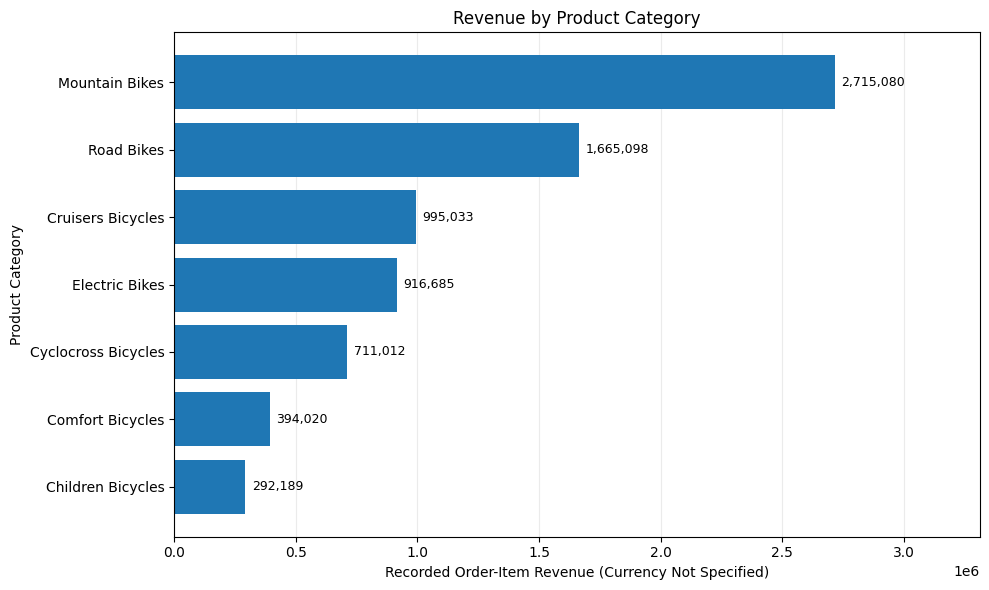

In [2]:
display(sales_by_category.sort_values("revenue", ascending=False).style.format({"revenue": "{:,.2f}", "units_sold": "{:,.0f}", "total_orders": "{:,.0f}"}))

plot_df = sales_by_category.sort_values("revenue", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_df["category_name"], plot_df["revenue"])
max_revenue = plot_df["revenue"].max()
for bar in bars:
    value = bar.get_width()
    ax.text(value + max_revenue * 0.01, bar.get_y() + bar.get_height()/2, f"{value:,.0f}", va="center", fontsize=9)
ax.set_title("Revenue by Product Category")
ax.set_xlabel("Recorded Order-Item Revenue (Currency Not Specified)")
ax.set_ylabel("Product Category")
ax.set_xlim(0, max_revenue * 1.22)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "revenue_by_product_category.png", bbox_inches="tight")
plt.show()

### 2.2 Revenue concentration and top products

Mountain Bikes generated the highest recorded category revenue, followed by Road Bikes. Together, the two categories account for 56.97% of all recorded order-item revenue. Cruisers Bicycles have the highest unit volume in the category summary.

In [3]:
display(revenue_share.sort_values("revenue_share_pct", ascending=False).style.format({"revenue": "{:,.2f}", "revenue_share_pct": "{:.2f}%"}))

# Compare the Top 10 ranks across all order-item records and shipped orders only.
top_all_ranked = top_products_all.copy().reset_index(drop=True)
top_all_ranked["rank_all_order_items"] = np.arange(1, len(top_all_ranked) + 1)
top_shipped_ranked = top_products_shipped.copy().reset_index(drop=True)
top_shipped_ranked["rank_shipped_orders"] = np.arange(1, len(top_shipped_ranked) + 1)
comparison = top_all_ranked[["product_name", "category_name", "units_sold", "revenue", "rank_all_order_items"]].merge(
    top_shipped_ranked[["product_name", "units_sold", "revenue", "rank_shipped_orders"]],
    on="product_name", how="outer", suffixes=("_all", "_shipped")
)
comparison = comparison.rename(columns={"units_sold_all":"units_all_order_items", "revenue_all":"revenue_all_order_items", "units_sold_shipped":"units_shipped_orders", "revenue_shipped":"revenue_shipped_orders"})
display(comparison.sort_values("rank_all_order_items").style.format({"revenue_all_order_items":"{:,.2f}", "revenue_shipped_orders":"{:,.2f}"}))

print("All top-10 products remain in the top 10 when restricting the calculation to orders with a recorded shipping date.")

,category_name,revenue,revenue_share_pct
0,Mountain Bikes,"2,715,079.53",35.31%
1,Road Bikes,"1,665,098.49",21.66%
2,Cruisers Bicycles,"995,032.62",12.94%
3,Electric Bikes,"916,684.78",11.92%
4,Cyclocross Bicycles,"711,011.84",9.25%
5,Comfort Bicycles,"394,020.10",5.12%
6,Children Bicycles,"292,189.20",3.80%


,product_name,category_name,units_all_order_items,revenue_all_order_items,rank_all_order_items,units_shipped_orders,revenue_shipped_orders,rank_shipped_orders
9,Trek Slash 8 27.5 - 2016,Mountain Bikes,154,"555,558.61",1,151,"544,318.64",1
2,Trek Conduit+ - 2016,Electric Bikes,145,"389,248.70",2,142,"381,148.73",2
4,Trek Fuel EX 8 29 - 2016,Mountain Bikes,143,"368,472.73",3,138,"354,813.78",3
1,Surly Straggler 650b - 2016,Cyclocross Bicycles,151,"226,765.55",4,147,"220,713.99",4
3,Trek Domane SLR 6 Disc - 2017,Road Bikes,43,"211,584.62",5,37,"181,279.67",7
0,Surly Straggler - 2016,Cyclocross Bicycles,147,"203,507.62",6,141,"195,669.68",6
7,Trek Remedy 29 Carbon Frameset - 2016,Mountain Bikes,125,"203,380.87",7,123,"199,996.89",5
6,Trek Powerfly 8 FS Plus - 2017,Electric Bikes,41,"188,249.62",8,35,"160,249.68",10
5,Trek Madone 9.2 - 2017,Road Bikes,39,"175,899.65",9,37,"166,599.67",9
8,Trek Silque SLR 8 Women's - 2017,Road Bikes,29,"174,524.73",10,28,"168,674.74",8


All top-10 products remain in the top 10 when restricting the calculation to orders with a recorded shipping date.


### 2.3 Category revenue from shipped orders

The following results restrict revenue to orders with a recorded shipping date. A recorded shipment date does not establish that the item was delivered to the customer or paid for.

In [4]:
display(shipped_revenue_by_category.sort_values("revenue", ascending=False).style.format({"revenue":"{:,.2f}", "shipped_orders":"{:,.0f}", "units_sold":"{:,.0f}"}))

,category_name,shipped_orders,units_sold,revenue
0,Mountain Bikes,788,"1,607","2,486,420.26"
1,Road Bikes,251,449,"1,327,155.64"
2,Cruisers Bicycles,865,"1,865","866,524.40"
3,Electric Bikes,164,252,"733,493.75"
4,Cyclocross Bicycles,228,365,"642,584.83"
5,Comfort Bicycles,425,733,"346,450.00"
6,Children Bicycles,563,"1,047","259,986.37"


## 3. Inventory analysis

The inventory snapshot date is not known. Differences between inventory share and shipped-revenue share should therefore be treated as signals for further investigation, not proof of overstocking or understocking.

,category_name,number_of_products,total_units_in_stock,number_of_stores
0,Cruisers Bicycles,78,3378,3
1,Mountain Bikes,60,2654,3
2,Children Bicycles,59,2608,3
3,Road Bikes,54,2091,3
4,Comfort Bicycles,28,1258,3
5,Electric Bikes,24,1108,3
6,Cyclocross Bicycles,10,414,3


,category_name,units_in_stock,inventory_share_pct,shipped_revenue,revenue_share_pct
0,Mountain Bikes,2654,19.64%,"2,486,420.26",37.32%
1,Road Bikes,2091,15.48%,"1,327,155.64",19.92%
2,Cruisers Bicycles,3378,25.00%,"866,524.40",13.01%
3,Electric Bikes,1108,8.20%,"733,493.75",11.01%
4,Cyclocross Bicycles,414,3.06%,"642,584.83",9.64%
5,Comfort Bicycles,1258,9.31%,"346,450.00",5.20%
6,Children Bicycles,2608,19.30%,"259,986.37",3.90%


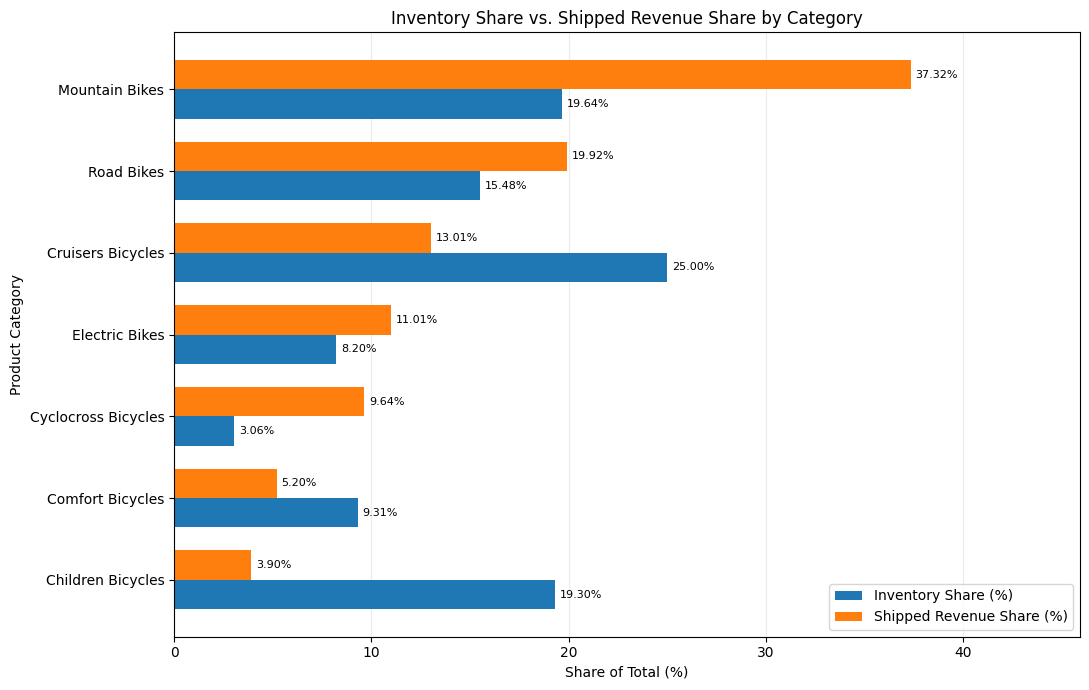

In [5]:
display(inventory_by_category.sort_values("total_units_in_stock", ascending=False))
display(inventory_vs_revenue.sort_values("revenue_share_pct", ascending=False).style.format({"inventory_share_pct":"{:.2f}%", "revenue_share_pct":"{:.2f}%", "shipped_revenue":"{:,.2f}"}))

plot_df = inventory_vs_revenue.sort_values("revenue_share_pct", ascending=True).reset_index(drop=True)
y = np.arange(len(plot_df))
bar_height = 0.36
fig, ax = plt.subplots(figsize=(11, 7))
inv_bars = ax.barh(y - bar_height/2, plot_df["inventory_share_pct"], height=bar_height, label="Inventory Share (%)")
rev_bars = ax.barh(y + bar_height/2, plot_df["revenue_share_pct"], height=bar_height, label="Shipped Revenue Share (%)")
for bars in (inv_bars, rev_bars):
    for bar in bars:
        value = bar.get_width()
        ax.text(value + 0.25, bar.get_y() + bar.get_height()/2, f"{value:.2f}%", va="center", fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels(plot_df["category_name"])
ax.set_title("Inventory Share vs. Shipped Revenue Share by Category")
ax.set_xlabel("Share of Total (%)")
ax.set_ylabel("Product Category")
ax.set_xlim(0, max(plot_df["inventory_share_pct"].max(), plot_df["revenue_share_pct"].max()) * 1.23)
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "inventory_vs_shipped_revenue_share.png", bbox_inches="tight")
plt.show()

## 4. Shipping performance

A shipment is classified as **Late** when `shipped_date > required_date`. All rates below use orders with a recorded shipping date only.

,shipped_orders,late_shipped_orders,on_time_shipped_orders,late_shipment_rate_pct
0,1445,458,987,31.70%


,shipping_status,order_count,percentage
0,On time,987,68.30%
1,Late,458,31.70%


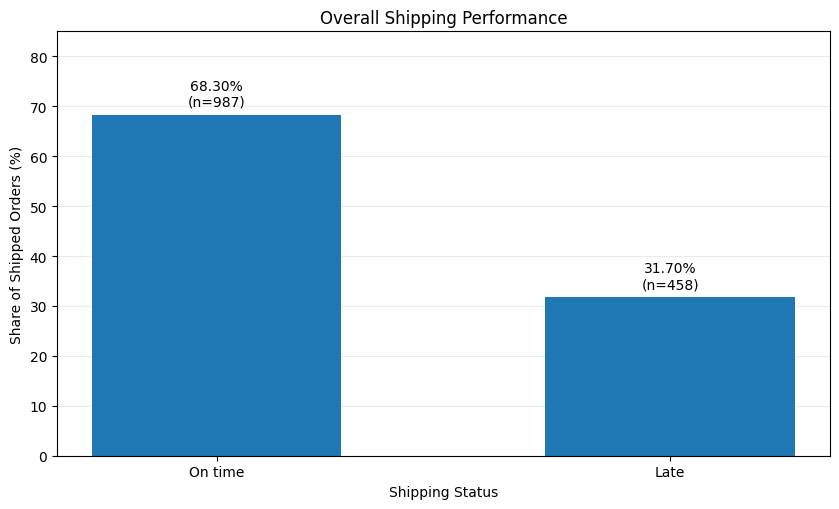

In [6]:
display(overall_shipping.style.format({"late_shipment_rate_pct":"{:.2f}%"}))
display(overall_shipping_split.style.format({"percentage":"{:.2f}%", "order_count":"{:,.0f}"}))

plot_df = overall_shipping_split.copy()
fig, ax = plt.subplots(figsize=(8.5, 5.2))
bars = ax.bar(plot_df["shipping_status"], plot_df["percentage"], width=0.55)
for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2, f"{row['percentage']:.2f}%\n(n={int(row['order_count']):,})", ha="center", va="bottom")
ax.set_title("Overall Shipping Performance")
ax.set_xlabel("Shipping Status")
ax.set_ylabel("Share of Shipped Orders (%)")
ax.set_ylim(0, 85)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "overall_shipping_performance.png", bbox_inches="tight")
plt.show()

### 4.1 Shipping performance by store

Santa Cruz Bikes has the highest late-shipment rate, while Baldwin Bikes has the highest number of late shipments and the largest shipment volume. These are descriptive differences and do not establish why delays occur.

,store_name,shipped_orders,late_shipped_orders,late_shipment_rate_pct
0,Santa Cruz Bikes,284,104,36.62%
1,Baldwin Bikes,"1,019",317,31.11%
2,Rowlett Bikes,142,37,26.06%


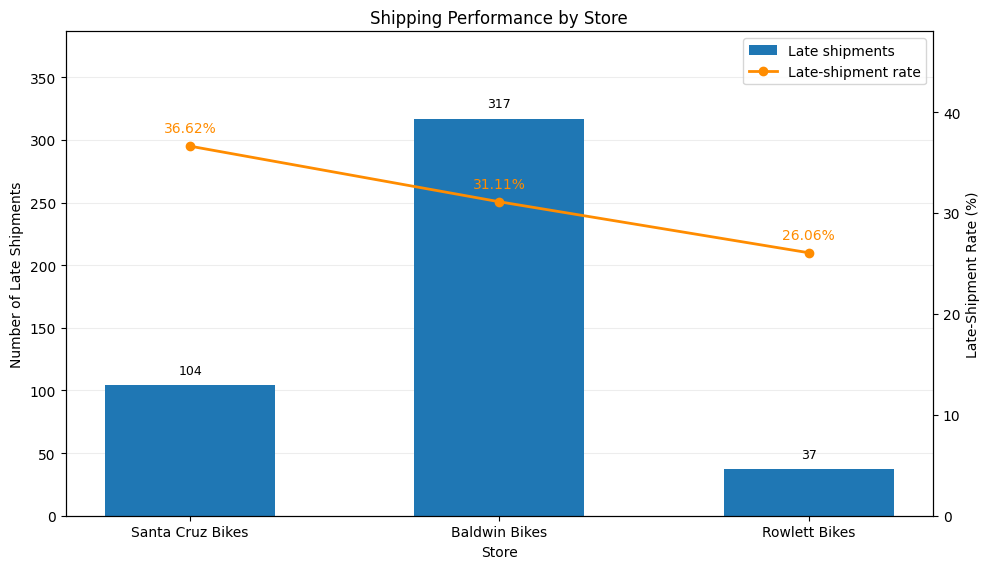

In [7]:
display(shipping_by_store.sort_values("late_shipment_rate_pct", ascending=False).style.format({"late_shipment_rate_pct":"{:.2f}%", "shipped_orders":"{:,.0f}", "late_shipped_orders":"{:,.0f}"}))

plot_df = shipping_by_store.sort_values("late_shipment_rate_pct", ascending=False)
fig, ax1 = plt.subplots(figsize=(10, 5.8))
bars = ax1.bar(plot_df["store_name"], plot_df["late_shipped_orders"], width=0.55, label="Late shipments")
for bar in bars:
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+7, f"{int(bar.get_height())}", ha="center", va="bottom", fontsize=9)
ax1.set_xlabel("Store")
ax1.set_ylabel("Number of Late Shipments")
ax1.set_ylim(0, plot_df["late_shipped_orders"].max()*1.22)
ax2 = ax1.twinx()
ax2.plot(plot_df["store_name"], plot_df["late_shipment_rate_pct"], marker="o", linewidth=2, color="darkorange", label="Late-shipment rate")
for store, rate in zip(plot_df["store_name"], plot_df["late_shipment_rate_pct"]):
    ax2.annotate(f"{rate:.2f}%", (store, rate), xytext=(0, 10), textcoords="offset points", ha="center", color="darkorange")
ax2.set_ylabel("Late-Shipment Rate (%)")
ax2.set_ylim(0, 48)
h1,l1 = ax1.get_legend_handles_labels()
h2,l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, loc="upper right")
ax1.set_title("Shipping Performance by Store")
ax1.grid(axis="y", alpha=0.22)
ax1.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "shipping_performance_by_store.png", bbox_inches="tight")
plt.show()

### 4.2 Annual trend and shipping-date coverage

Annual results are grouped by **order year**, not shipment year. The apparent increase in the late-shipment rate should be interpreted cautiously because only 52.74% of 2018 orders have a recorded shipping date.

,order_year,shipped_orders,late_shipped_orders,late_shipment_rate_pct
0,2016,620,191,30.81%
1,2017,671,215,32.04%
2,2018,154,52,33.77%


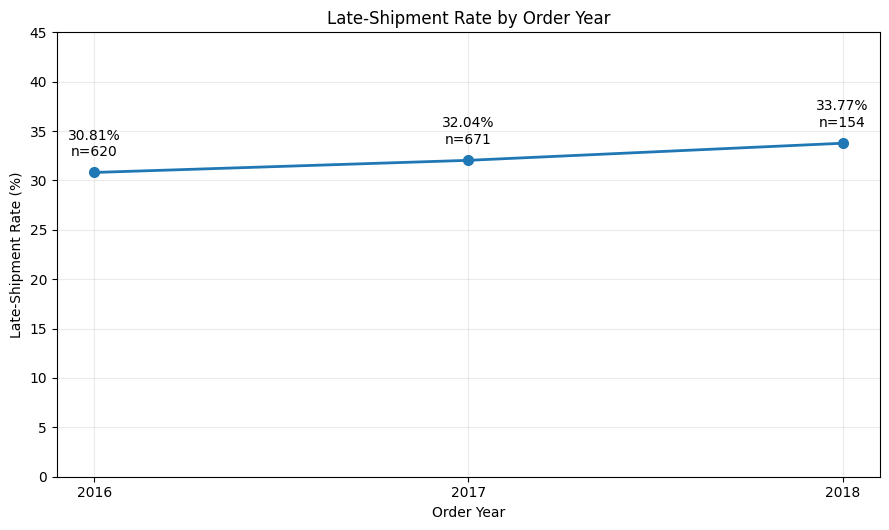

,order_year,total_orders,shipped_orders,orders_without_shipped_date,shipping_date_coverage_pct
0,2016,635,620,15,97.64%
1,2017,688,671,17,97.53%
2,2018,292,154,138,52.74%


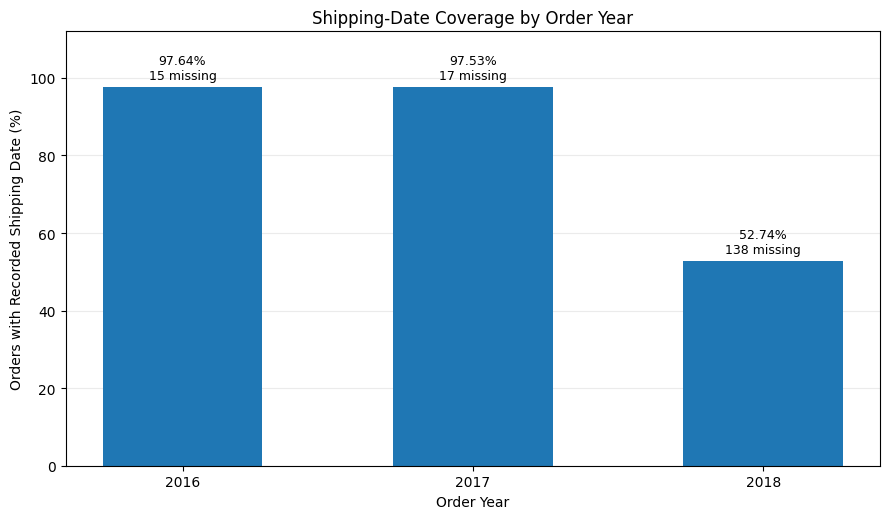

In [8]:
display(annual_shipping.sort_values("order_year").style.format({"late_shipment_rate_pct":"{:.2f}%", "shipped_orders":"{:,.0f}", "late_shipped_orders":"{:,.0f}"}))
plot_df = annual_shipping.sort_values("order_year")
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.plot(plot_df["order_year"], plot_df["late_shipment_rate_pct"], marker="o", linewidth=2, markersize=7)
for _, row in plot_df.iterrows():
    ax.annotate(f"{row['late_shipment_rate_pct']:.2f}%\nn={int(row['shipped_orders']):,}", (row["order_year"], row["late_shipment_rate_pct"]), xytext=(0, 12), textcoords="offset points", ha="center")
ax.set_title("Late-Shipment Rate by Order Year")
ax.set_xlabel("Order Year")
ax.set_ylabel("Late-Shipment Rate (%)")
ax.set_xticks(plot_df["order_year"].tolist())
ax.set_ylim(0,45)
ax.grid(True,alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "annual_late_shipment_rate.png", bbox_inches="tight")
plt.show()

display(shipping_coverage.sort_values("order_year").style.format({"shipping_date_coverage_pct":"{:.2f}%", "total_orders":"{:,.0f}", "shipped_orders":"{:,.0f}", "orders_without_shipped_date":"{:,.0f}"}))
plot_df = shipping_coverage.sort_values("order_year")
fig, ax = plt.subplots(figsize=(9, 5.3))
bars = ax.bar(plot_df["order_year"].astype(str), plot_df["shipping_date_coverage_pct"], width=0.55)
for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.4, f"{row['shipping_date_coverage_pct']:.2f}%\n{int(row['orders_without_shipped_date'])} missing", ha="center", va="bottom", fontsize=9)
ax.set_title("Shipping-Date Coverage by Order Year")
ax.set_xlabel("Order Year")
ax.set_ylabel("Orders with Recorded Shipping Date (%)")
ax.set_ylim(0,112)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "shipping_date_coverage_by_order_year.png", bbox_inches="tight")
plt.show()

### 4.3 Monthly pattern

Months are based on `order_date` year and month; the denominator includes shipped orders only. The 2018 series contains January–March only. The observed fluctuations do not establish seasonality or explain causes.

,order_year,order_month,shipped_orders,late_shipped_orders,late_shipment_rate_pct
0,2016,1,50,13,26.00%
1,2016,2,47,16,34.04%
2,2016,3,55,11,20.00%
3,2016,4,41,17,41.46%
4,2016,5,49,15,30.61%
5,2016,6,44,13,29.55%
6,2016,7,50,15,30.00%
7,2016,8,59,20,33.90%
8,2016,9,66,17,25.76%
9,2016,10,64,22,34.38%


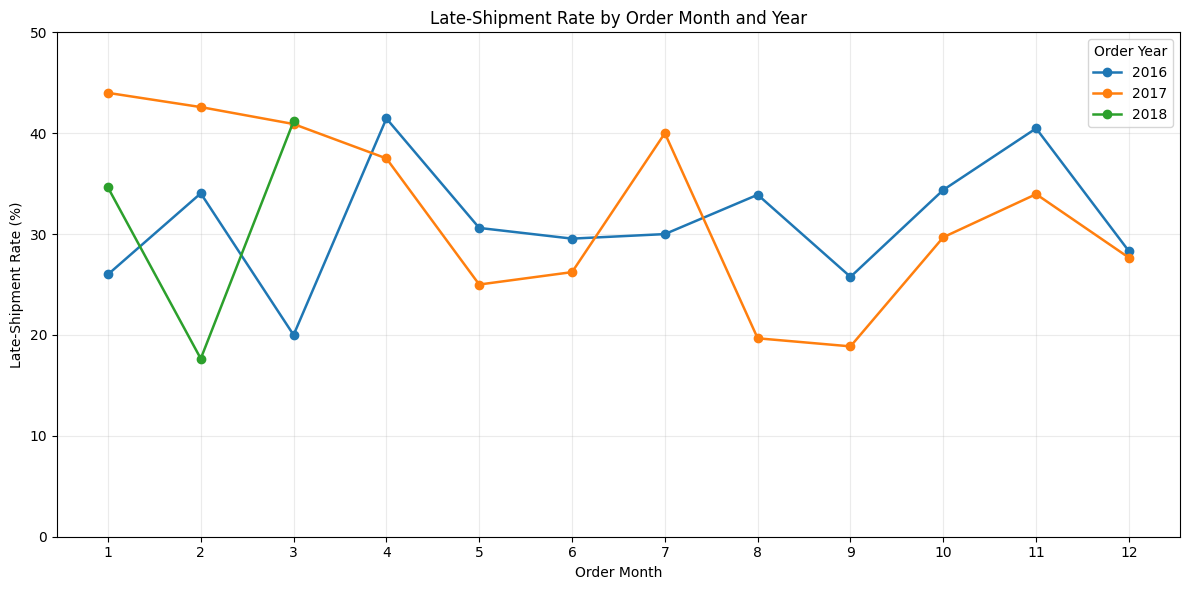

In [9]:
display(monthly_shipping.sort_values(["order_year", "order_month"]).style.format({"late_shipment_rate_pct":"{:.2f}%", "shipped_orders":"{:,.0f}", "late_shipped_orders":"{:,.0f}"}))
plot_df = monthly_shipping.sort_values(["order_year", "order_month"])
fig, ax = plt.subplots(figsize=(12, 6))
for year, group in plot_df.groupby("order_year"):
    ax.plot(group["order_month"], group["late_shipment_rate_pct"], marker="o", linewidth=1.8, label=str(year))
ax.set_title("Late-Shipment Rate by Order Month and Year")
ax.set_xlabel("Order Month")
ax.set_ylabel("Late-Shipment Rate (%)")
ax.set_xticks(range(1,13))
ax.set_ylim(0,50)
ax.grid(True, alpha=0.25)
ax.legend(title="Order Year")
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "monthly_late_shipment_rate.png", bbox_inches="tight")
plt.show()

## 5. Key business insights and recommendations

### Key insights

1. **Revenue concentration:** Mountain Bikes and Road Bikes generated 56.97% of recorded order-item revenue. Mountain Bikes led revenue, while Cruisers Bicycles led unit volume.
2. **Inventory versus revenue:** Mountain Bikes and Road Bikes accounted for 57.24% of shipped revenue but 35.12% of recorded inventory. Cruisers Bicycles and Children Bicycles accounted for 44.30% of inventory and 16.91% of shipped revenue.
3. **Shipping timeliness:** 458 of 1,445 shipped orders (31.70%) were shipped after the required date. Santa Cruz Bikes had the highest late-shipment rate (36.62%), while Baldwin Bikes had the highest late-shipment count (317).
4. **Data completeness:** Shipping-date coverage fell to 52.74% in 2018, limiting direct comparison with 2016 and 2017.

### Recommendations

- Review inventory at product and store level alongside stock turnover, demand trends, and replenishment lead times before changing allocations.
- Investigate shipping processes at Santa Cruz Bikes and examine both volume and rate at Baldwin Bikes.
- Monitor late-shipment rates monthly and by store using consistent KPIs.
- Improve completeness and consistency of order and shipping-date records.

### Limitations

- The dataset does not identify currency.
- The stock snapshot date is unknown.
- A recorded shipment date does not confirm customer delivery or payment.
- Shipping-date coverage in 2018 is incomplete.
- The analysis identifies associations and patterns; it does not establish causal explanations for delays or inventory differences.